<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🗺️ 2026-10 对照：本课的手搓实现 ↔ deepagents 官方 deep research，以及「新版」到底新了什么

**一句话定位**：这门课（2025-07）教你用 LangGraph 原语**手搓**一个 deep research 系统；到 2026-10，LangChain 官方的 deep research 实现已经改用 **deepagents** 封装，Open Deep Research 仓库归档。手搓的每个零件在 deepagents 里都有对应物，**设计原则一条没变**。
> 事实来源：上游 git log、本机两套 venv（langgraph 1.2.0 / deepagents 0.7.0）、docs.langchain.com deepagents/deep-research 页面、deepagents/examples/deep_research（2026-10-21 核实）。

</div>

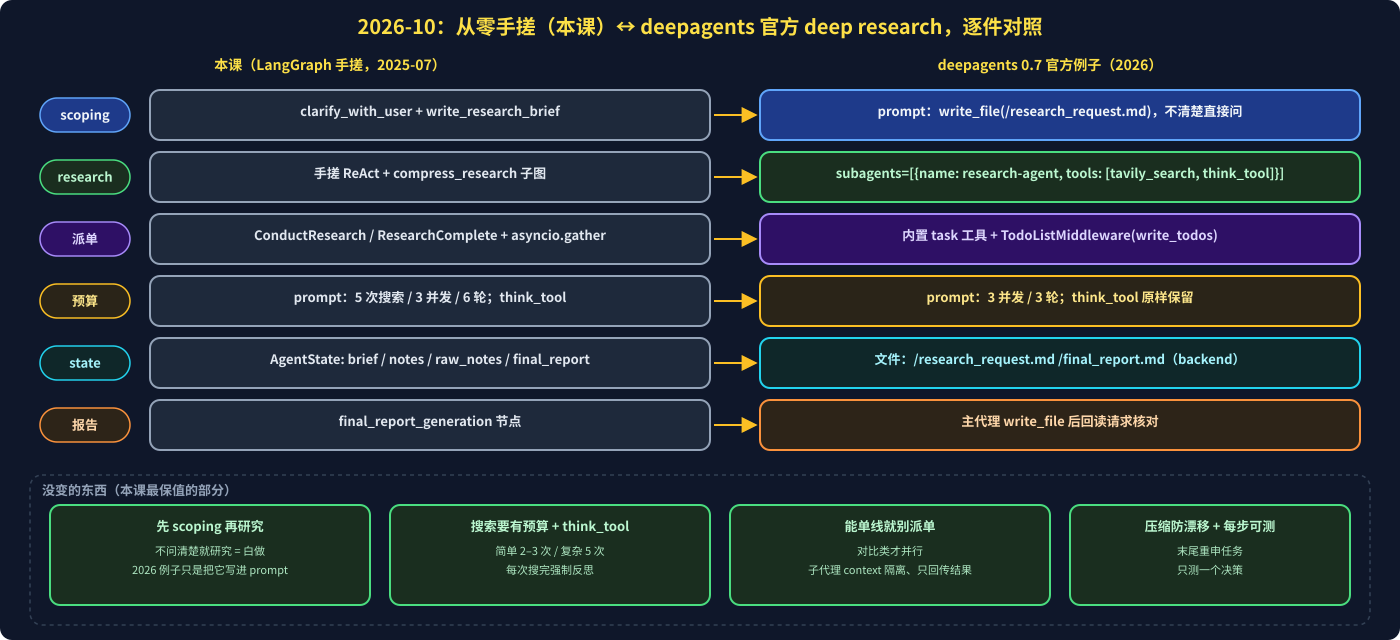

In [ ]:
from IPython.display import SVG
SVG(filename="assets/06_vs_deepagents.svg")

### 1️⃣ 「新版」`deep-research-new`（已删除）其实没有新内容

| 上游提交 | 日期 | 改了什么 | 对你这份的影响 |
|---|---|---|---|
| `Update pyproject.toml` | 2025-10-21 | 依赖改 `langgraph>=1.0.0` / `langchain>=1.0.0`，**未重新 lock**（`uv.lock` 仍 langgraph 0.6.2 / langchain 0.3.26） | 你的 `.venv` 已是 1.2.0 / 1.3.1，10 个模块 import 无警告 |
| `Migrate sonnet-4 to sonnet-4-6` | 2026-06-14 | 模型名 | 已同步 |
| `Add MIT LICENSE` | 2026-06-15 | 许可证 | 无 |
| `Migrate expiring LangSmith traces` | 2026-08-10 | 7 条公开 trace 链接 | 本次已刷新 |

notebook 代码逐 cell 对比：差异只有格式、`load_dotenv(override=True)`、画图曲线样式、你加的 `sys.path`。**没有任何 API 升级或新章节。** 本地克隆 `deep-research-new` 已于 2026-10-21 删除；需要时从 GitHub 重新 clone。

### 2️⃣ 官方 2026 实现长什么样（deepagents 0.7）

In [ ]:
from deepagents import create_deep_agent
from langchain.agents.middleware import TodoListMiddleware
from langchain.chat_models import init_chat_model

model = init_chat_model(model="anthropic:claude-sonnet-4-5-20250929", temperature=0.0)   # 例子里的默认；可换 Claude 5 系列

research_sub_agent = {
    "name": "research-agent",
    "description": "Delegate research to the sub-agent. Give one topic at a time.",
    "system_prompt": RESEARCHER_INSTRUCTIONS.format(date=current_date),     # 搜索预算 + think_tool 规则，和本课 2_a 同款
    "tools": [tavily_search, think_tool],
}
agent = create_deep_agent(
    model=model,
    tools=[tavily_search, think_tool],
    system_prompt=RESEARCH_WORKFLOW_INSTRUCTIONS + "=" * 80
                  + SUBAGENT_DELEGATION_INSTRUCTIONS.format(max_concurrent_research_units=3, max_researcher_iterations=3),
    subagents=[research_sub_agent],
    middleware=[TodoListMiddleware()],                                     # write_todos：0.7 起 opt-in
)

| 本课零件 | deepagents 对应物 | 备注 |
|---|---|---|
| `clarify_with_user` / `write_research_brief` 节点 | 无节点；prompt 要求 `write_file("/research_request.md")`，不清楚就问用户 | 本课显式建模更可测 |
| `researcher_agent` 子图（ReAct + compress） | `subagents=[...]`，子代理只回传最终消息 | 压缩 = 不回传轨迹 |
| `ConductResearch` / `ResearchComplete` | 内置 `task` 工具；不发 tool_calls 即结束 | |
| `asyncio.gather` | ToolNode 并发执行多个 `task` | |
| `research_iterations` 计数 + prompt 限制 | 只靠 prompt（3 并发 / 3 轮）+ `write_todos` 规划 | |
| `AgentState` 字段 | backend 里的文件 `/research_request.md`、`/final_report.md` | StateBackend / FilesystemBackend / Sandbox 可换 |
| `final_report_generation` 节点 | 主代理自己 `write_file` 报告，再回读请求核对覆盖度 | |
| `recursion_limit` | `create_deep_agent` 内部设 9999 | |
| `think_tool`、搜索预算、「先宽后窄」 | **原样沿用** | |

### 3️⃣ 时间线

| 时间 | 事件 |
|---|---|
| 2025-07 | 本课发布（langgraph 0.6，claude-sonnet-4 / gpt-4.1） |
| 2025-08-14 | Open Deep Research 更新并链接本课仓库 |
| 2025-10 | LangGraph / LangChain 1.0；上游 pyproject 跟进但未 relock |
| 2026-06-14 | 上游改模型名 sonnet-4-6 |
| 2026-08-10 | 上游刷新 trace 链接 |
| 2026-08-21 | **Open Deep Research 仓库归档**；官方实现 = deepagents/examples/deep_research |
| 2026-10-21 | 本笔记核实：langgraph 1.2.0 / langchain 1.3.1 / mcp-adapters 0.2.2；deepagents 0.7 |

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**什么时候仍然该用本课的手搓写法**

- 需要**把每个决策做成可单测的节点**（scoping 的 bool 路由、supervisor 的并行判断）—— deepagents 里这些都藏在 prompt 和 middleware 里。
- 需要**自定义 state 字段和子图输出 schema**（`raw_notes` 留底、`output_schema` 收窄）。
- 想真正理解 deepagents 在做什么：它的 `task` 工具、Summarization、子代理隔离，就是本课 2_a / 4_a 的封装版。

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：`deep-research-new` = 上游克隆，**没有新内容**；真正的「新」是 **deepagents 把本课的 supervisor / 子代理 / 压缩全部内置**（`task` + `subagents` + `TodoListMiddleware`）。但 **scoping 先行、搜索预算 + think_tool、能单线就别派、压缩防漂移、每步可测** 这五条原则一字未改 —— 这门课教的是原则，框架只是载体。

</div>